# 03 — Hybrid model MZA-FAO + machine learning

Predicts second-season maize yield (IBGE/PAM) from the MZA-FAO simulation (notebook 02) and compares
several formulations, all validated by **leaving one whole year out** (23 folds, 2003–2025):

| | Model | Features |
|---|---|---|
| A | Historical mean | technology trend + municipality effect |
| B | Calibrated MZA | A + linear regression: ISNA at flowering and grain filling + frost severity |
| C | Pure ML | A + shallow gradient boosting on **raw weather** per phase (rain, Tmin, Tmax) + altitude and DTA |
| D | Hybrid | A + the same gradient boosting on **MZA variables** (water efficiency PA/PPf, ISNA, deficit, frost, heat) + altitude and DTA |
| E | Physics-guided MZA hybrid | D with **monotonic constraints**: yield increasing with ISNA and PA/PPf, decreasing with deficit, frost and heat |
| F | APSIM hybrid | the same monotonic gradient boosting on **APSIM NG** variables (simulated yield, grain number, cumulative water stress per period, Tmin in the phases) |
| H | AquaCrop hybrid | same, with **AquaCrop** variables (simulated and potential yield, transpiration stress per period, Tmin) |
| I | DSSAT hybrid | same, with **DSSAT CERES-Maize** variables (simulated yield, biomass, water stress per period, days to anthesis, Tmin) |
| J | Hybrid with all | variables of the four models together |
| K | MZA hybrid with SVR | D variables without PA/PPf and flowering deficit, with *support vector regression* (RBF kernel): smooth response, no monotonic constraint |
| **L** | **Ensemble E + K (final model)** | mean, in log, of the E and K predictions |

**Hypothesis**: does an uncalibrated, more complex process-based model generate better features for the
hybrid model than the simple MZA-FAO? All use the same inputs (BR-DWGD weather, soil profile from AWC +
MapBiomas Soil), the same sowing window and the same ML; only the feature generator changes
(E × F × H × I). Since the MZA features were designed with agronomic reasoning (and refined on these
data), section 2.2 repeats the comparison with an **identical automatic feature selection** for the four
generators: with it, MZA, APSIM and DSSAT perform alike and AquaCrop is worse. The conclusion is that
the simplest model, uncalibrated, is as informative as APSIM and DSSAT; the gain of the final model
comes from agronomically designed features, physical constraints in the ML and the ensemble.

C and D have the same algorithm and the same number of features: the difference measures the
information gain from MZA. Deep trees with dozens of features (ExtraTrees, 70 features) memorize the
years — with 22 training years, the weather signal is annual and regional, and the model must be
parsimonious.

**Algorithm.** In a separate comparison, with the same features as D and the same validation, HGB,
XGBoost, LightGBM, Random Forest, ExtraTrees, Ridge with splines, MLP and SVR were tested, in default,
shallow/regularized and nested-tuned configurations (grid evaluated on blocks of years within the
training set of each fold). All ranged between R² 0.37 and 0.44; the default configurations were the
worst (they memorize the years) and fine tuning barely changed the result. SVR was the best single
algorithm (nested tuning chose C = 0.3 and γ = 0.05 in 22 of the 23 folds), and the SVR + monotonic HGB
mean (L) was the only improvement with a confidence interval excluding zero — the two err differently
(smooth × stepwise response) and half of the ensemble keeps the physical constraints. Since SVR is
unconstrained, PA/PPf and the flowering deficit (r = 0.97 and −0.92 with flowering ISNA) are removed
from it: with all three, SVR split the water effect with opposite signs and PA/PPf got an effect
contrary to physics (section 5.1); without them, all variables keep their physical direction, at a
cost of 0.01 in R².

**Target.** log yield. Technology trend (linear in year) and municipality fixed effect are estimated
only with the training years of each fold; the model predicts the **anomaly** relative to them.

**Sowing dates.** IBGE does not report the sowing date; the municipal yield mixes the sowings of the
window. In training, each model's features are means over 4 window dates (15/01, 05/02, 25/02, 15/03).
In the prediction per date, the features of that date are used. The monotonic constraints of E ensure
that the response to each date's features has the expected physical direction when the model is
applied away from the window mean.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

plt.rcParams.update({"font.size": 16})

from sensibilidade import PARAM, SAIDA, SENS, entrada

RAIZ = Path.cwd().parent
DADOS, RESULTADOS, FIGURAS = RAIZ / "dados", RAIZ / "resultados", RAIZ / "figuras"
if SENS:
    FIGURAS = SAIDA
SEMENTE = 42

FASES = ["estabelecimento", "vegetativo", "floracao", "enchimento", "maturacao"]
ORDEM_DATAS = [f"{d:02d}/{m:02d}" for m in (1, 2, 3) for d in (5, 15, 25)]
JANELA = ["15/01", "05/02", "25/02", "15/03"]  # same 4 dates simulated by all models
AREA_MIN_HA = 100  # drops municipality-years with residual second season (unrepresentative yield)

sim = pd.read_parquet(entrada("simulacao_mza_pr.parquet"))
# Cycles that do not close before winter (cold plateau) leave phases without data: counts = 0,
# other variables = phase median (only affects municipalities without second-season records).
fase_cols = [c for c in sim.columns if any(c.endswith("_" + f) for f in ["estabelecimento", "vegetativo", "floracao", "enchimento", "maturacao"])]
contagens = [c for c in fase_cols if c.startswith(("geada_", "calor_"))]
sim[contagens] = sim[contagens].fillna(0)
sim[fase_cols] = sim[fase_cols].fillna(sim[fase_cols].median())
print("Combinations with incomplete cycle:", int(sim["ciclo_incompleto"].sum()))
sim["EC"] = sim["PA"] / sim["PPf"]  # water efficiency: fraction of PPf preserved by the water balance
sim["geada_reprod"] = sim["geada_floracao"] + sim["geada_enchimento"]
sim["calor_reprod"] = sim["calor_floracao"] + sim["calor_enchimento"]
sim["frio_reprod"] = np.clip(2 - sim[["Tmin_floracao", "Tmin_enchimento"]].min(axis=1), 0, None)  # °C below 2

mun = pd.read_csv(DADOS / "municipios_pr.csv")
pam = pd.read_csv(DADOS / "ibge_pam_milho_pr.csv")
pam = pam[(pam["safra"] == 2) & (pam["rendimento_kg_ha"] > 0) & (pam["area_colhida_ha"] >= AREA_MIN_HA)]
# Values identical to the previous year (8.5%) indicate a repeated estimate, not a survey: removed from training
pam = pam.sort_values(["cod_ibge", "ano"])
pam = pam[~(pam.groupby("cod_ibge")["rendimento_kg_ha"].diff() == 0)]

apsim = pd.read_parquet(RESULTADOS / "simulacao_apsim_pr.parquet")
apsim["ap_log_rend"] = np.log(apsim["ap_rend"].clip(lower=100))
aquacrop = pd.read_parquet(RESULTADOS / "simulacao_aquacrop_pr.parquet")
aquacrop["aq_log_rend"] = np.log(aquacrop["aq_rend"].clip(lower=100))
aquacrop["aq_razao_pot"] = aquacrop["aq_razao_pot"].fillna(0)
dssat = pd.read_parquet(RESULTADOS / "simulacao_dssat_pr.parquet")
dssat["ds_log_rend"] = np.log(dssat["ds_rend"].clip(lower=100))
print(f"IBGE second season: {len(pam)} municipality-years, {pam['cod_ibge'].nunique()} municipalities, "
      f"{pam['ano'].min()}–{pam['ano'].max()}")

Combinations with incomplete cycle: 0
IBGE second season: 6806 municipality-years, 373 municipalities, 2003–2025


## 1. Features

In [2]:
VAR_ESTATICO = ["altitude_m", "dta_mm_m", "latitude", "longitude"]
VAR_FISICO = ["ISNA_floracao", "ISNA_enchimento", "frio_reprod"]                       # model B
VAR_CLIMA = [f"{v}_{f}" for f in ["vegetativo", "floracao", "enchimento"] for v in ["chuva", "Tmin", "Tmax"]]  # C
# D/E: variable, physical direction (+1 increasing, −1 decreasing, 0 free)
VAR_MZA = {"EC": 1, "ISNA_vegetativo": 1, "ISNA_floracao": 1, "ISNA_enchimento": 1, "DEF_floracao": -1,
           "frio_reprod": -1, "geada_reprod": -1, "calor_floracao": -1}
VAR_APSIM = {"ap_log_rend": 1, "ap_n_graos": 1, "ap_estresse_veg": -1, "ap_estresse_flor": -1,
             "ap_estresse_ench": -1, "ap_tmin_flor": 0, "ap_tmin_ench": 0, "ap_ciclo_dias": 0}
VAR_AQ = {"aq_log_rend": 1, "aq_razao_pot": 1, "aq_estresse_veg": -1, "aq_estresse_flor": -1,
          "aq_estresse_ench": -1, "aq_tmin_flor": 0, "aq_tmin_ench": 0, "aq_ciclo_dias": 0}
VAR_DS = {"ds_log_rend": 1, "ds_biomassa": 1, "ds_estresse_veg": -1, "ds_estresse_flor": -1,
          "ds_estresse_ench": -1, "ds_tmin_flor": 0, "ds_tmin_ench": 0, "ds_dias_antese": 0}
VARS_D = list(VAR_MZA) + VAR_ESTATICO
MONO = list(VAR_MZA.values()) + [0] * len(VAR_ESTATICO)
VARS_F = list(VAR_APSIM) + VAR_ESTATICO
MONO_F = list(VAR_APSIM.values()) + [0] * len(VAR_ESTATICO)
def conjunto(*dicts):
    nomes = [k for d in dicts for k in d] + VAR_ESTATICO
    return nomes, [v for d in dicts for v in d.values()] + [0] * len(VAR_ESTATICO)


VARS_H, MONO_H = conjunto(VAR_AQ)
VARS_I, MONO_I = conjunto(VAR_DS)
VARS_J, MONO_J = conjunto(VAR_MZA, VAR_APSIM, VAR_AQ, VAR_DS)
FASE_COLS_TODAS = [f"{v}_{f}" for f in FASES for v in ["chuva", "Tmed", "Tmax", "Tmin", "Rs", "UR", "ISNA", "DEF", "EXC", "geada", "calor"]]

# MZA variables: weighted mean of the window dates (equal weights on the 4 dates, except in the sensitivity runs)
PESOS_JANELA = PARAM.get("pesos_janela", {d: 1.0 for d in JANELA})
cols_mza = sorted(set(FASE_COLS_TODAS + list(VAR_MZA) + VAR_FISICO + ["calor_reprod"]))
jm = sim[sim["semeadura"].isin(PESOS_JANELA)]
w = jm["semeadura"].map(PESOS_JANELA)
chave = [jm["cod_ibge"], jm["ano"]]
media_janela = (jm[cols_mza].mul(w, axis=0).groupby(chave).sum()
                .div(w.groupby(chave).sum(), axis=0).reset_index())
def media_da_janela(df, variaveis):
    return df[df["semeadura"].isin(JANELA)].groupby(["cod_ibge", "ano"])[list(variaveis)].mean().reset_index()


janela_apsim = media_da_janela(apsim, VAR_APSIM)
base = (pam[["cod_ibge", "ano", "rendimento_kg_ha", "area_colhida_ha"]]
        .merge(media_janela, on=["cod_ibge", "ano"])
        .merge(janela_apsim, on=["cod_ibge", "ano"])
        .merge(media_da_janela(aquacrop, VAR_AQ), on=["cod_ibge", "ano"])
        .merge(media_da_janela(dssat, VAR_DS), on=["cod_ibge", "ano"])
        .merge(mun[["cod_ibge", "municipio", "mesorregiao_oeste"] + VAR_ESTATICO], on="cod_ibge"))
base["log_y"] = np.log(base["rendimento_kg_ha"])
print(base.shape)

(6806, 94)


## 2. Leave-one-year-out validation

In [3]:
def tendencia_e_municipio(treino):
    """log_y = a + b·year + municipality effect, estimated on the training set only."""
    reg = LinearRegression().fit(treino[["ano"]], treino["log_y"])
    resid = treino["log_y"] - reg.predict(treino[["ano"]])
    efeito = resid.groupby(treino["cod_ibge"]).mean()
    return reg, efeito


def base_prevista(df, reg, efeito):
    return reg.predict(df[["ano"]]) + df["cod_ibge"].map(efeito).fillna(0).to_numpy()


def gbm(monotonico=None):
    # Shallow, regularized gradient boosting (the weather signal is annual: few degrees of freedom).
    return HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, min_samples_leaf=100,
                                         l2_regularization=1.0, monotonic_cst=monotonico, random_state=SEMENTE)


VARS_SVR = [v for v in VARS_D if v not in ("EC", "DEF_floracao")]  # without the variables collinear with ISNA


def svr():
    # RBF kernel; C and γ chosen by nested tuning (validation on blocks of years within each fold)
    return make_pipeline(StandardScaler(), SVR(C=0.3, gamma=0.05, epsilon=0.05))


MODELOS = {
    "A_media_historica": None,
    "B_MZA_calibrado": "fisico",
    "C_ML_puro": (VAR_CLIMA + VAR_ESTATICO, None),
    "D_hibrido": (VARS_D, None),
    "E_hibrido_monotonico": (VARS_D, MONO),
    "F_hibrido_apsim": (VARS_F, MONO_F),
    "H_hibrido_aquacrop": (VARS_H, MONO_H),
    "I_hibrido_dssat": (VARS_I, MONO_I),
    "J_hibrido_todos": (VARS_J, MONO_J),
    "K_hibrido_svr": (VARS_SVR, "svr"),
}
FINAL = "L_ensemble_E_SVR"  # mean (log) of E and K
HIBRIDOS = ["E_hibrido_monotonico", "F_hibrido_apsim", "H_hibrido_aquacrop", "I_hibrido_dssat"]

oof = base[["cod_ibge", "ano", "rendimento_kg_ha", "log_y", "mesorregiao_oeste"]].copy()
for ano in sorted(base["ano"].unique()):
    tr, te = base["ano"] != ano, base["ano"] == ano
    reg, efeito = tendencia_e_municipio(base[tr])
    b_tr, b_te = base_prevista(base[tr], reg, efeito), base_prevista(base[te], reg, efeito)
    anom_tr = base.loc[tr, "log_y"] - b_tr

    fis = LinearRegression().fit(base.loc[tr, VAR_FISICO], anom_tr)
    fis_te = fis.predict(base.loc[te, VAR_FISICO])

    for nome, spec in MODELOS.items():
        if spec is None:
            anom = 0.0
        elif spec == "fisico":
            anom = fis_te
        else:
            cols, mono = spec
            modelo = svr() if mono == "svr" else gbm(mono)
            anom = modelo.fit(base.loc[tr, cols], anom_tr).predict(base.loc[te, cols])
        oof.loc[te, nome] = b_te + anom

oof[FINAL] = oof[["E_hibrido_monotonico", "K_hibrido_svr"]].mean(axis=1)
nomes = list(MODELOS) + [FINAL]
print("ok")

ok


In [4]:
def metricas(df, col):
    y, p = df["rendimento_kg_ha"], np.exp(df[col])
    anual = df.assign(p=p).groupby("ano")[["rendimento_kg_ha", "p"]].mean()
    return {
        "R2": r2_score(y, p),
        "RMSE_kg_ha": float(np.sqrt(np.mean((y - p) ** 2))),
        "MAE_kg_ha": mean_absolute_error(y, p),
        "r_anual_estadual": anual.corr().iloc[0, 1],
        "R2_anual_estadual": r2_score(anual["rendimento_kg_ha"], anual["p"]),
    }


tab = pd.DataFrame({n: metricas(oof, n) for n in nomes}).T
ref = tab.loc["A_media_historica", "RMSE_kg_ha"]
tab["ganho_sobre_A_%"] = 100 * (1 - tab["RMSE_kg_ha"] / ref)
tab.to_csv(SAIDA / "validacao_loyo_modelos.csv")
tab.round(3)

,R2,RMSE_kg_ha,MAE_kg_ha,r_anual_estadual,R2_anual_estadual,ganho_sobre_A_%
A_media_historica,0.259,1207.017,955.907,0.595,0.313,0.000
B_MZA_calibrado,0.353,1128.278,883.079,0.774,0.587,6.523
C_ML_puro,0.318,1157.767,909.709,0.757,0.554,4.080
D_hibrido,0.403,1083.899,848.491,0.820,0.656,10.200
E_hibrido_monotonico,0.394,1091.816,849.891,0.803,0.634,9.544
F_hibrido_apsim,0.334,1144.514,904.799,0.728,0.513,5.178
H_hibrido_aquacrop,0.245,1218.148,958.477,0.665,0.422,-0.922
I_hibrido_dssat,0.334,1144.196,895.043,0.735,0.523,5.205
J_hibrido_todos,0.350,1130.186,887.358,0.756,0.560,6.365
K_hibrido_svr,0.420,1067.953,830.975,0.828,0.682,11.521


### Are the differences between feature generators real?

Bootstrap over **years** (years are the independent unit of the validation; 2,000 resamples): for each
hybrid, the RMSE difference relative to the MZA hybrid (E). A 95% interval not crossing zero indicates a
difference robust to the choice of years.

In [5]:
rng_b = np.random.default_rng(SEMENTE)
anos_u = np.sort(oof["ano"].unique())
erro2 = {n: (oof["rendimento_kg_ha"] - np.exp(oof[n])) ** 2 for n in nomes}
por_ano = pd.DataFrame({n: e.groupby(oof["ano"]).sum() for n, e in erro2.items()})
cont = oof.groupby("ano").size()
amostras = rng_b.choice(anos_u, size=(2000, len(anos_u)))
rmse_boot = {n: np.sqrt(por_ano[n].to_numpy()[np.searchsorted(anos_u, amostras)].sum(1)
                        / cont.to_numpy()[np.searchsorted(anos_u, amostras)].sum(1)) for n in nomes}
ref_b = rmse_boot["E_hibrido_monotonico"]
boot = pd.DataFrame({n: {"dif_RMSE_vs_E": np.median(rmse_boot[n] - ref_b),
                         "IC95_inf": np.percentile(rmse_boot[n] - ref_b, 2.5),
                         "IC95_sup": np.percentile(rmse_boot[n] - ref_b, 97.5),
                         "P(melhor que E)": np.mean(rmse_boot[n] < ref_b)} for n in nomes if n != "E_hibrido_monotonico"}).T
boot.to_csv(SAIDA / "comparacao_geradores_bootstrap.csv")
boot.round(2)

,dif_RMSE_vs_E,IC95_inf,IC95_sup,P(melhor que E)
A_media_historica,108.35,-57.13,285.36,0.10
B_MZA_calibrado,36.56,-36.14,102.69,0.14
C_ML_puro,65.19,-23.19,152.59,0.07
D_hibrido,-6.88,-44.40,27.18,0.66
F_hibrido_apsim,51.30,-1.43,110.20,0.03
H_hibrido_aquacrop,123.13,0.12,254.19,0.02
I_hibrido_dssat,51.62,10.54,93.60,0.01
J_hibrido_todos,38.63,9.58,65.00,0.00
K_hibrido_svr,-23.71,-69.73,18.89,0.85
L_ensemble_E_SVR,-30.07,-52.40,-8.83,1.00


### 2.2 Robustness: identical automatic feature selection for the four generators

The hand-picked MZA features were defined after exploratory tests on these data, whereas those of APSIM,
AquaCrop and DSSAT were defined once. To remove this advantage, the same automatic rule is applied to all
generators **inside each fold** (training years only): the k candidates with the highest |Spearman r| with
the training anomaly, skipping candidates with |r| > 0.9 with one already chosen; the same shallow HGB
without constraints (the direction of automatically chosen variables is not known beforehand). Candidate
pools contain only process outputs (MZA: PPf, PA, PA/PPf, cycle length, and ISNA, deficit, surplus,
frost, heat and Tmin per phase; APSIM, AquaCrop, DSSAT: all their cycle variables).

In [6]:
from joblib import Parallel, delayed

POOL_MZA = (["PPf", "PA", "EC", "ciclo_dias", "geada_reprod", "calor_reprod", "frio_reprod"]
            + [f"{v}_{f}" for f in FASES for v in ["ISNA", "DEF", "EXC", "geada", "calor", "Tmin"]])
POOLS = {"MZA": (sim, POOL_MZA)}
for nome, df, pref in [("APSIM", apsim, "ap_"), ("AquaCrop", aquacrop, "aq_"), ("DSSAT", dssat, "ds_")]:
    POOLS[nome] = (df, [c for c in df.columns if c.startswith(pref) and df[c].dtype.kind in "fi" and not c.endswith("log_rend")])
base_sel = pam[["cod_ibge", "ano", "rendimento_kg_ha"]].merge(mun[["cod_ibge"] + VAR_ESTATICO], on="cod_ibge")
for nome, (df, cols) in POOLS.items():
    base_sel = base_sel.merge(media_da_janela(df, cols), on=["cod_ibge", "ano"])
base_sel["log_y"] = np.log(base_sel["rendimento_kg_ha"])
base_sel = base_sel.dropna().reset_index(drop=True)
print("Municipality-years:", len(base_sel), "| pool sizes:", {k: len(v[1]) for k, v in POOLS.items()})


def seleciona(X, y, k, limite=0.9):
    """Top-k by |Spearman r| with the anomaly, skipping variables redundant with those already chosen."""
    r = X.rank().corrwith(y.rank()).abs().sort_values(ascending=False)
    escolhidas = []
    for c in r.index:
        if all(abs(X[c].corr(X[e], method="spearman")) <= limite for e in escolhidas):
            escolhidas.append(c)
        if len(escolhidas) == k:
            break
    return escolhidas


KS = [8, 12]


def dobra_sel(ano):
    tr, te = base_sel["ano"] != ano, base_sel["ano"] == ano
    reg, ef = tendencia_e_municipio(base_sel[tr])
    b_te = base_prevista(base_sel[te], reg, ef)
    anom = base_sel.loc[tr, "log_y"] - base_prevista(base_sel[tr], reg, ef)
    out = {}
    for g, (_, cols) in POOLS.items():
        for k in KS:
            X = seleciona(base_sel.loc[tr, cols], anom, min(k, len(cols))) + VAR_ESTATICO
            out[f"{g}_k{k}"] = b_te + gbm(None).fit(base_sel.loc[tr, X], anom).predict(base_sel.loc[te, X])
    return te.to_numpy(), out


oof_sel = base_sel[["cod_ibge", "ano", "rendimento_kg_ha", "log_y"]].copy()
with np.errstate(invalid="ignore", divide="ignore"):  # constant candidates in some folds
    for te, out in Parallel(n_jobs=4)(delayed(dobra_sel)(a) for a in sorted(base_sel["ano"].unique())):
        for n_, v in out.items():
            oof_sel.loc[te, n_] = v
mods_sel = [f"{g}_k{k}" for k in KS for g in POOLS]
tab_sel = pd.DataFrame({c: metricas(oof_sel, c) for c in mods_sel}).T[["R2", "RMSE_kg_ha", "R2_anual_estadual"]]
anos_s = np.sort(oof_sel["ano"].unique())
ix_s = np.searchsorted(anos_s, np.random.default_rng(SEMENTE).choice(anos_s, (2000, len(anos_s))))
cont_s = oof_sel.groupby("ano").size().to_numpy()


def rmse_boot_sel(c):
    e = ((oof_sel["rendimento_kg_ha"] - np.exp(oof_sel[c])) ** 2).groupby(oof_sel["ano"]).sum().to_numpy()
    return np.sqrt(e[ix_s].sum(1) / cont_s[ix_s].sum(1))


for k in KS:
    ref_s = rmse_boot_sel(f"MZA_k{k}")
    for g in POOLS:
        d = rmse_boot_sel(f"{g}_k{k}") - ref_s
        tab_sel.loc[f"{g}_k{k}", ["dif_RMSE_vs_MZA", "IC95_inf", "IC95_sup"]] = [np.median(d), *np.percentile(d, [2.5, 97.5])]
tab_sel.to_csv(SAIDA / "selecao_automatica_geradores.csv")
tab_sel.round(3)

Municipality-years: 6787 | pool sizes: {'MZA': 37, 'APSIM': 12, 'AquaCrop': 12, 'DSSAT': 10}


/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-p

/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-p

/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


...

/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,R2,RMSE_kg_ha,R2_anual_estadual,dif_RMSE_vs_MZA,IC95_inf,IC95_sup
MZA_k8,0.326,1151.674,0.478,0.000,0.000,0.000
APSIM_k8,0.319,1157.624,0.481,6.119,-38.851,51.287
AquaCrop_k8,0.245,1218.554,0.418,69.358,-63.996,173.258
DSSAT_k8,0.330,1147.798,0.523,-3.725,-43.929,32.884
MZA_k12,0.337,1141.694,0.513,0.000,0.000,0.000
APSIM_k12,0.304,1169.493,0.451,28.114,-18.607,73.939
AquaCrop_k12,0.245,1218.369,0.421,78.504,-65.703,192.320
DSSAT_k12,0.330,1147.798,0.523,6.593,-33.423,40.630


### Performance by year (what matters for risk: getting the failure years right)

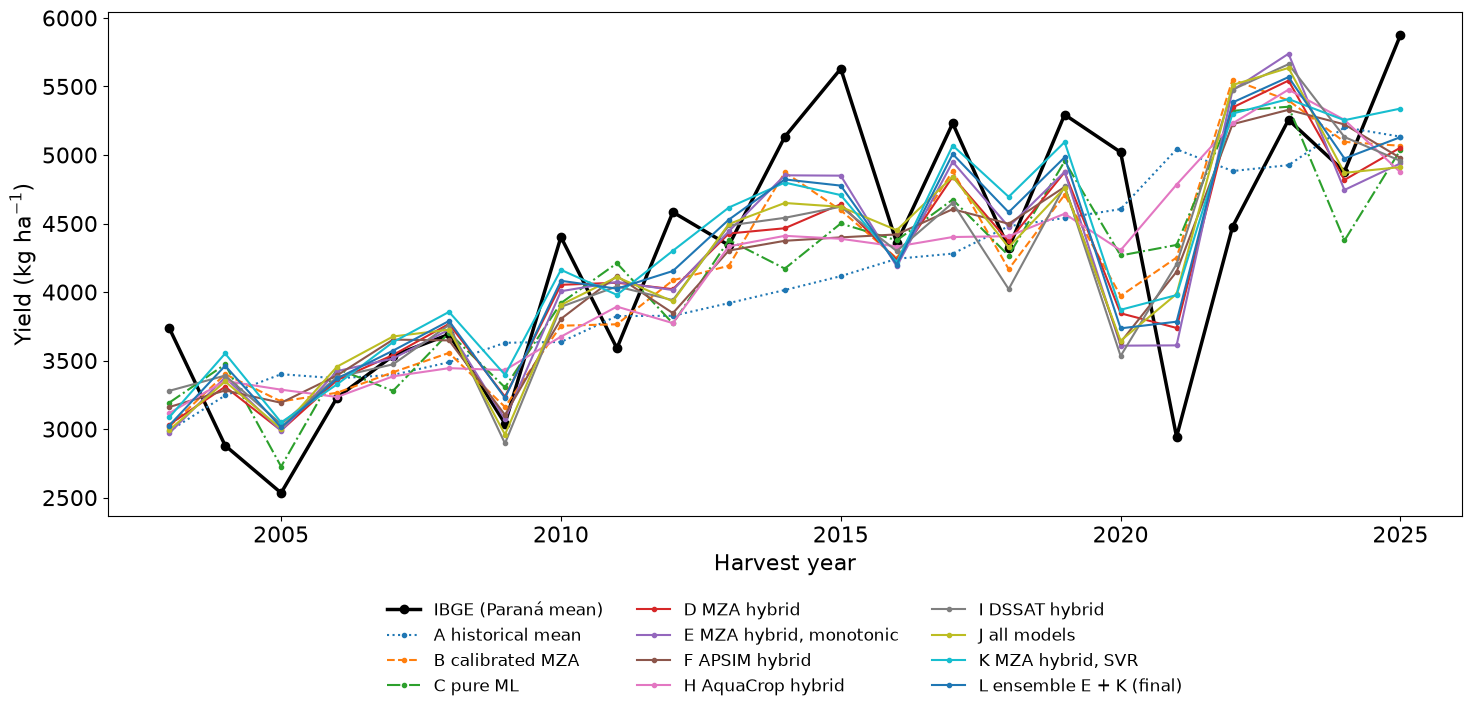

In [7]:
anual = oof.assign(**{n: np.exp(oof[n]) for n in nomes}).groupby("ano")[["rendimento_kg_ha"] + nomes].mean()
ROTULO = {"A_media_historica": "A historical mean", "B_MZA_calibrado": "B calibrated MZA", "C_ML_puro": "C pure ML",
          "D_hibrido": "D MZA hybrid", "E_hibrido_monotonico": "E MZA hybrid, monotonic", "F_hibrido_apsim": "F APSIM hybrid",
          "H_hibrido_aquacrop": "H AquaCrop hybrid", "I_hibrido_dssat": "I DSSAT hybrid", "J_hibrido_todos": "J all models",
          "K_hibrido_svr": "K MZA hybrid, SVR", "L_ensemble_E_SVR": "L ensemble E + K (final)"}
fig, ax = plt.subplots(figsize=(15, 7.5))
ax.plot(anual.index, anual["rendimento_kg_ha"], "ko-", lw=2.5, label="IBGE (Paraná mean)")
estilos = {"A_media_historica": ":", "B_MZA_calibrado": "--", "C_ML_puro": "-."}
for n in nomes:
    ax.plot(anual.index, anual[n], estilos.get(n, "-"), marker=".", label=ROTULO[n])
ax.set(xlabel="Harvest year", ylabel="Yield (kg ha$^{-1}$)")
ax.legend(frameon=False, ncol=3, fontsize=12, loc="upper center", bbox_to_anchor=(0.5, -0.14))
plt.tight_layout()
fig.savefig(FIGURAS / "fig_validacao_anual.png", dpi=300)

## 3. Prediction intervals (conformal)

For each test year, the quantiles come from the residuals (in log) of the **other** years —
leave-one-year-out conformal. The nominal 80% coverage (P10–P90) is checked year by year.

In [8]:
# Winning feature generator among the monotonic hybrids (E, F, H, I) → combined with SVR (L)
GERADOR = tab.loc[HIBRIDOS, "RMSE_kg_ha"].idxmin()
MELHOR = FINAL
VARS_FINAL, MONO_FINAL = MODELOS[GERADOR]
print("Lowest RMSE:", tab["RMSE_kg_ha"].idxmin(), "| generator:", GERADOR, "| final model:", MELHOR)
res = oof["log_y"] - oof[MELHOR]
q = {}
for ano in sorted(oof["ano"].unique()):
    r = res[oof["ano"] != ano]
    q[ano] = r.quantile([0.10, 0.50, 0.90]).to_numpy()
qa = oof["ano"].map(q)
oof["P10"] = np.exp(oof[MELHOR] + qa.str[0])
oof["P50"] = np.exp(oof[MELHOR] + qa.str[1])
oof["P90"] = np.exp(oof[MELHOR] + qa.str[2])
dentro = oof["rendimento_kg_ha"].between(oof["P10"], oof["P90"])
print(f"Final model: {MELHOR}; P10–P90 coverage = {dentro.mean():.1%} (nominal 80%)")
oof.to_parquet(SAIDA / "previsoes_fora_amostra.parquet", index=False)
dentro.groupby(oof["ano"]).mean().round(2).to_frame("cobertura").T

Lowest RMSE: L_ensemble_E_SVR | generator: E_hibrido_monotonico | final model: L_ensemble_E_SVR
Final model: L_ensemble_E_SVR; P10–P90 coverage = 79.4% (nominal 80%)


ano,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
cobertura,0.62,0.76,0.64,0.77,0.83,0.9,0.81,0.91,0.87,0.86,...,0.78,0.91,0.85,0.88,0.41,0.54,0.69,0.87,0.86,0.78


## 4. Analyses by phenological phase

### 4.1 Variables by phase × sowing date

semeadura,05/01,15/01,25/01,05/02,15/02,25/02,05/03,15/03,25/03
ciclo_dias,105.20,109.69,115.79,124.13,132.58,140.59,146.81,153.46,158.49
EC,0.43,0.37,0.33,0.30,0.28,0.28,0.29,0.30,0.31
geada_reprod,0.04,0.12,0.29,0.57,0.89,1.21,1.42,1.55,1.52


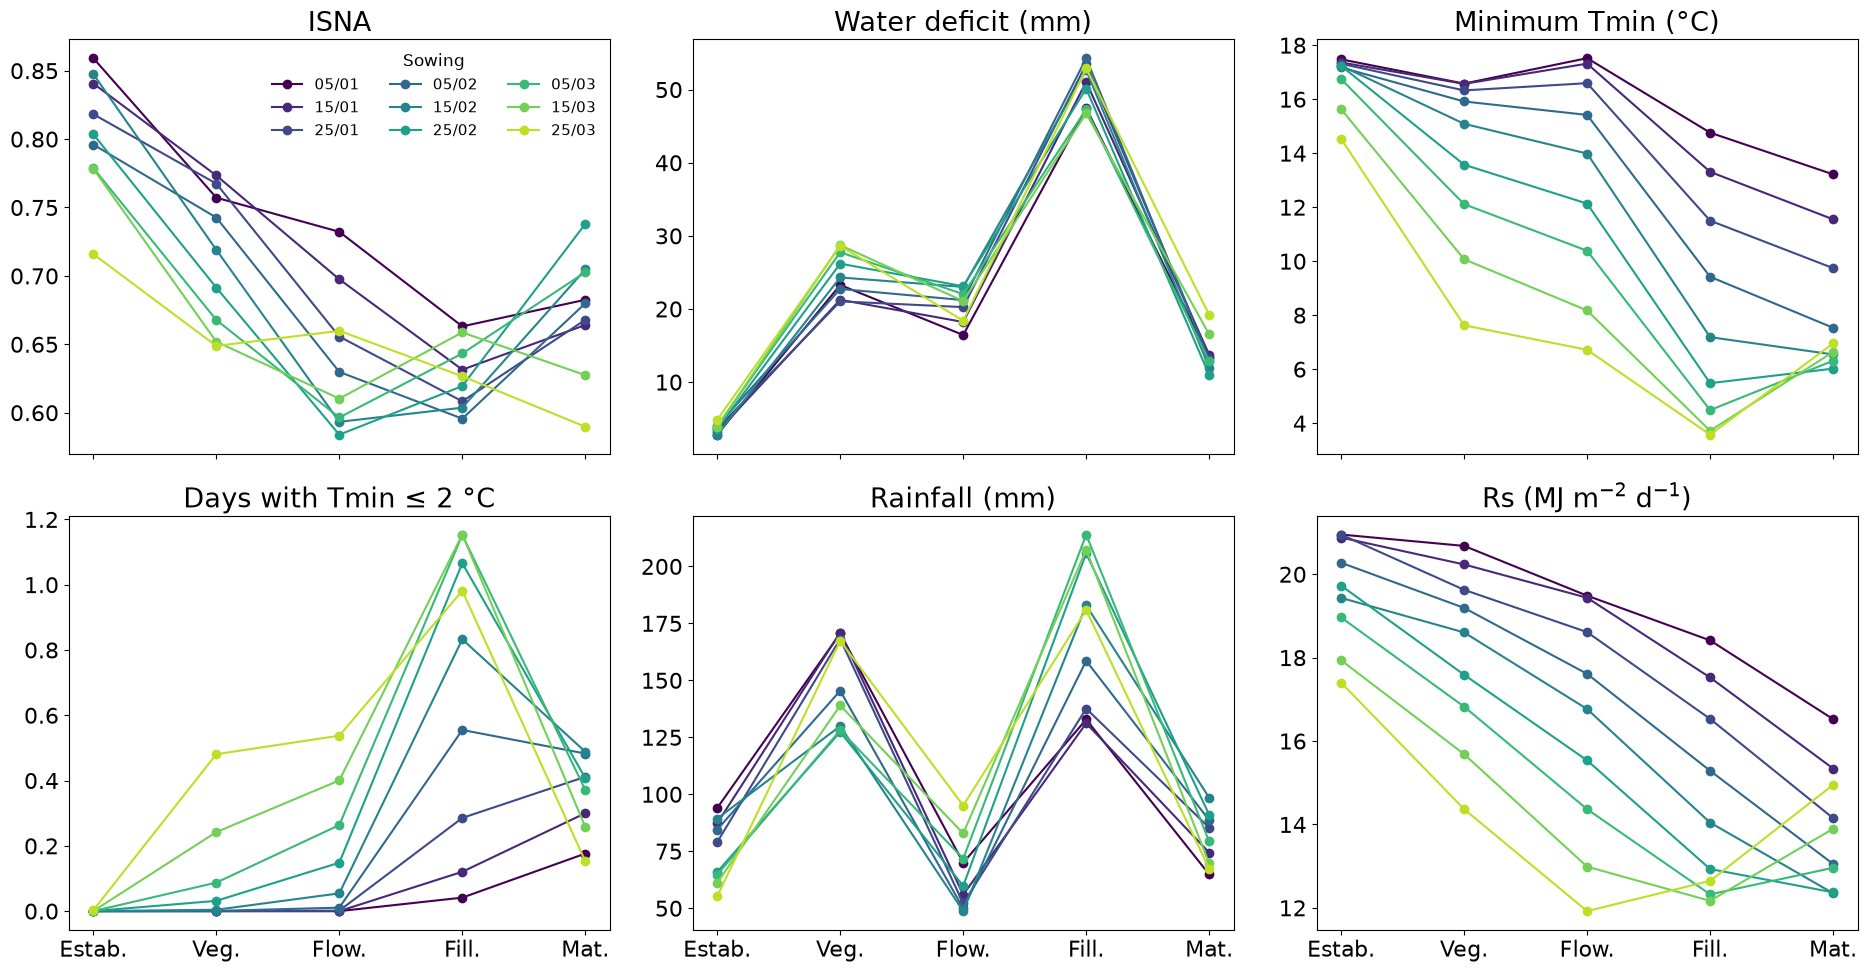

In [9]:
FASES_ROT = ["Estab.", "Veg.", "Flow.", "Fill.", "Mat."]
VARS_FIG = [("ISNA", "ISNA"), ("DEF", "Water deficit (mm)"), ("Tmin", "Minimum Tmin (°C)"),
            ("geada", "Days with Tmin ≤ 2 °C"), ("chuva", "Rainfall (mm)"), ("Rs", "Rs (MJ m$^{-2}$ d$^{-1}$)")]
fig, axs = plt.subplots(2, 3, figsize=(19, 10), sharex=True)
cores = plt.cm.viridis(np.linspace(0, 0.9, len(ORDEM_DATAS)))
for ax, (v, rot) in zip(axs.flat, VARS_FIG):
    med = sim.groupby("semeadura")[[f"{v}_{f}" for f in FASES]].mean().loc[ORDEM_DATAS]
    for (data, linha), c in zip(med.iterrows(), cores):
        ax.plot(range(len(FASES)), linha.values, marker="o", color=c, label=data)
    ax.set_title(rot)
    ax.set_xticks(range(len(FASES)), FASES_ROT)
axs[0, 0].legend(fontsize=11, ncol=3, frameon=False, title="Sowing", title_fontsize=12)
plt.tight_layout()
fig.savefig(FIGURAS / "fig_variaveis_fase_data.png", dpi=300)
sim.groupby("semeadura")[["ciclo_dias", "EC", "geada_reprod"]].mean().loc[ORDEM_DATAS].round(2).T

### 4.2 Correlation by phase with the yield anomaly

Split into two scales: **between years** (state means per year) and **between municipalities** (within
each year, mean of the correlations). The anomaly is the residual of model A fitted with all years.

/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-p

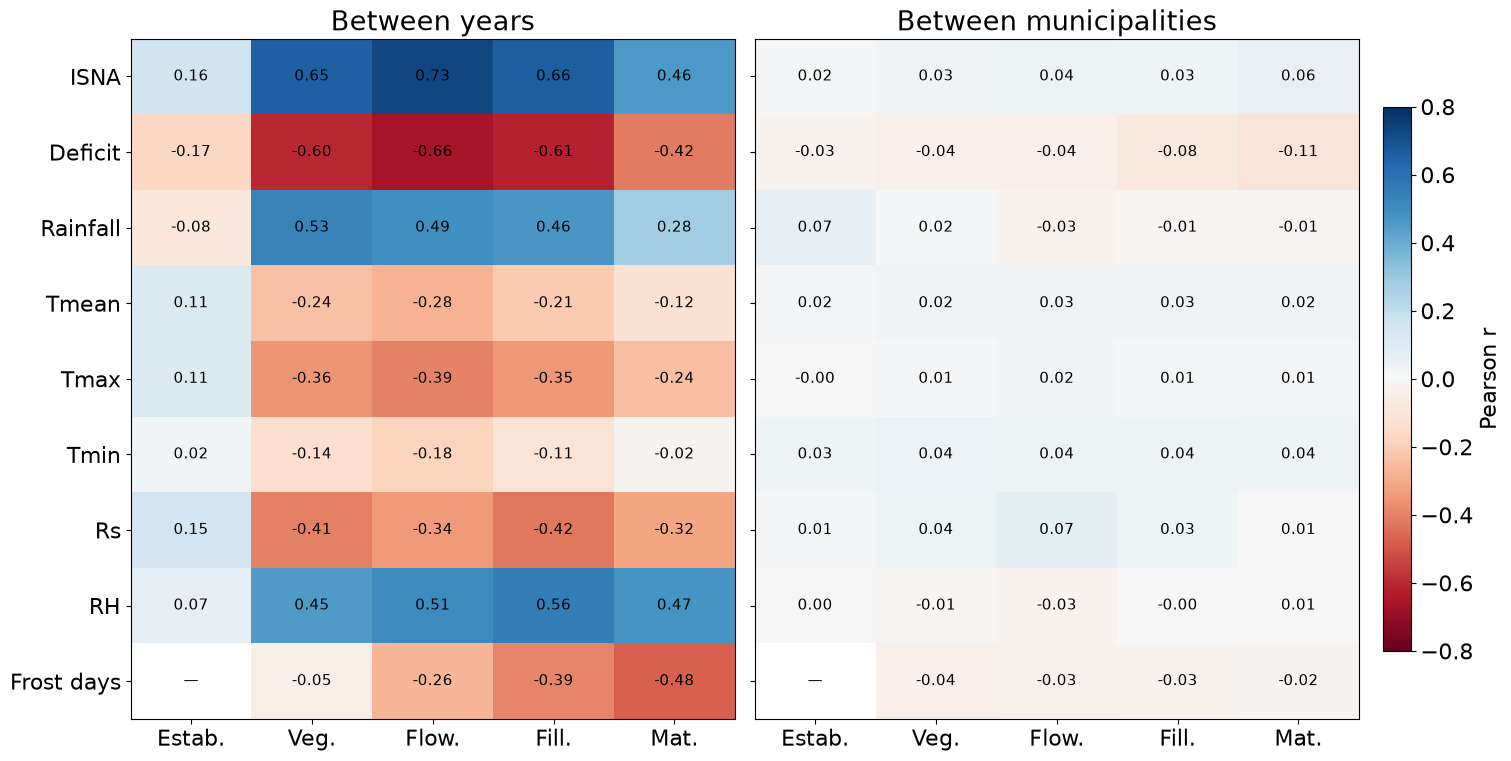

In [10]:
reg_all, efeito_all = tendencia_e_municipio(base)
base["anomalia"] = base["log_y"] - base_prevista(base, reg_all, efeito_all)
VARS_COR = ["ISNA", "DEF", "chuva", "Tmed", "Tmax", "Tmin", "Rs", "UR", "geada"]
linhas = []
for v in VARS_COR:
    for f in FASES:
        col = f"{v}_{f}"
        anual_m = base.groupby("ano")[["anomalia", col]].mean()
        espacial = base.groupby("ano").apply(lambda g: g["anomalia"].corr(g[col]), include_groups=False).mean()
        linhas.append({"variavel": v, "fase": f, "entre_anos": anual_m.corr().iloc[0, 1], "entre_municipios": espacial})
cor = pd.DataFrame(linhas)
cor.to_csv(SAIDA / "correlacao_fase.csv", index=False)

VARS_COR_ROT = ["ISNA", "Deficit", "Rainfall", "Tmean", "Tmax", "Tmin", "Rs", "RH", "Frost days"]
ESCALA_ROT = {"entre_anos": "Between years", "entre_municipios": "Between municipalities"}
fig, axs = plt.subplots(1, 2, figsize=(15, 7.5), sharey=True, layout="constrained")
for ax, escala in zip(axs, ["entre_anos", "entre_municipios"]):
    m = cor.pivot(index="variavel", columns="fase", values=escala).loc[VARS_COR, FASES]
    im = ax.imshow(m, cmap="RdBu", vmin=-0.8, vmax=0.8, aspect="auto")
    ax.set_xticks(range(len(FASES)), ["Estab.", "Veg.", "Flow.", "Fill.", "Mat."])
    ax.set_yticks(range(len(VARS_COR)), VARS_COR_ROT)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, "—" if np.isnan(m.iat[i, j]) else f"{m.iat[i, j]:.2f}", ha="center", va="center", fontsize=11)
    ax.set_title(ESCALA_ROT[escala])
fig.colorbar(im, ax=axs, shrink=0.8, label="Pearson r", pad=0.02)
fig.savefig(FIGURAS / "fig_correlacao_fase.png", dpi=300, bbox_inches="tight")

### 4.3 Importance by phase (SHAP of the final model, ensemble E + SVR)

SHAP is linear in the model: the ensemble's SHAP is the mean of each component's SHAP — exact
(TreeSHAP) for HGB and by permutation for SVR (2 antithetic permutations per row, background of 40
municipality-years; SVR predicts ~1,400 rows/s, which limits the sample to 200 municipality-years).

/Users/coted-sh/Python/ML_maize_pr/.venv313/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model B (all years): {'ISNA_floracao': np.float64(0.7), 'ISNA_enchimento': np.float64(0.3435), 'frio_reprod': np.float64(-0.0699)}


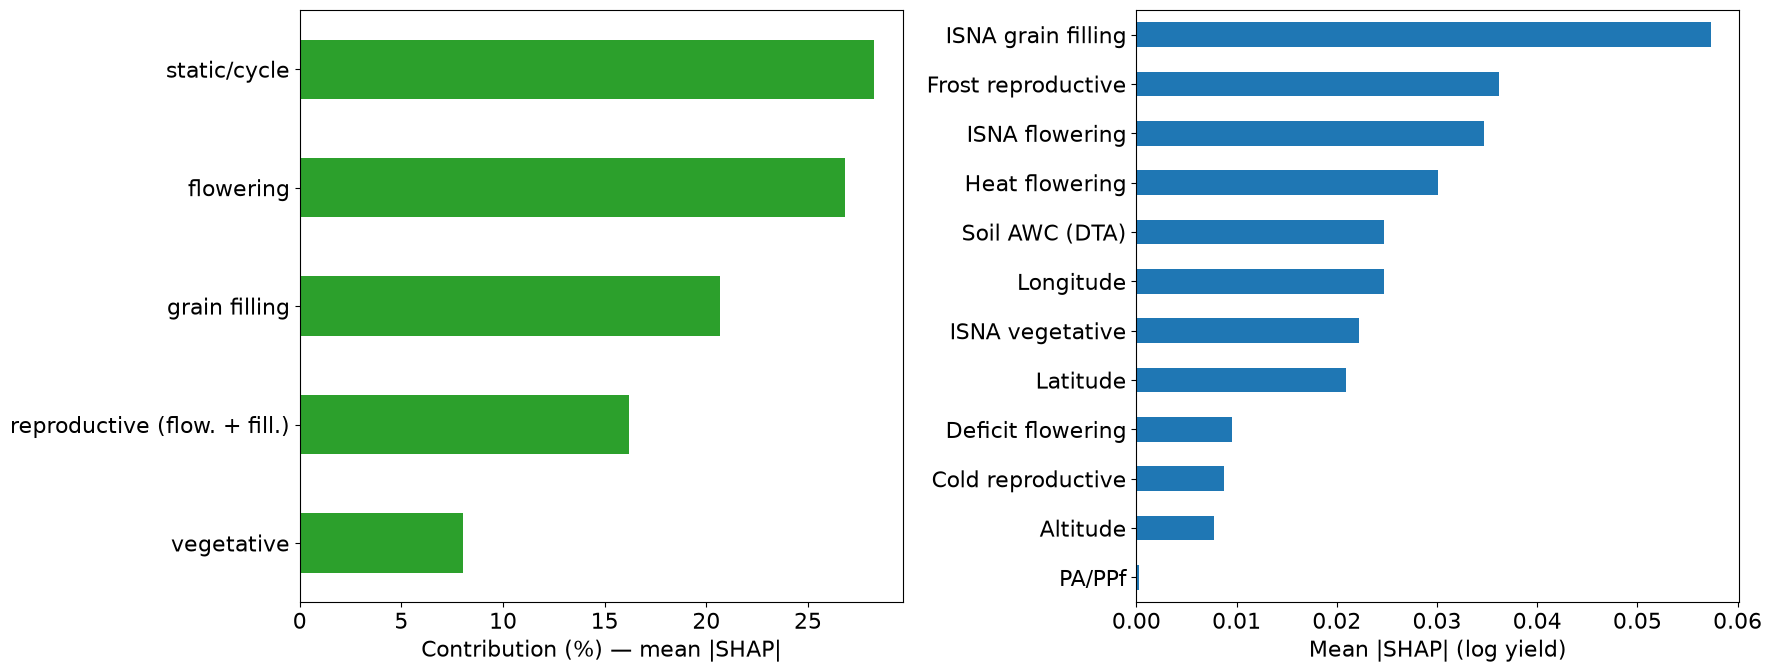

In [11]:
import shap

anom_all = base["anomalia"]
X = base[VARS_FINAL]
ml_final = gbm(MONO_FINAL).fit(X, anom_all)
svr_final = svr().fit(X[VARS_SVR], anom_all)


def prever_svr(x):
    return svr_final.predict(pd.DataFrame(x, columns=VARS_FINAL)[VARS_SVR])


def prever_final(x):
    x = pd.DataFrame(x, columns=VARS_FINAL)
    return (ml_final.predict(x) + prever_svr(x)) / 2


amostra = X.sample(200, random_state=SEMENTE)
shap_hgb = shap.TreeExplainer(ml_final).shap_values(amostra)
expl_svr = shap.PermutationExplainer(svr_final.predict, X[VARS_SVR].sample(40, random_state=SEMENTE + 1))
shap_svr = pd.DataFrame(0.0, index=amostra.index, columns=VARS_FINAL)  # EC and DEF are not SVR inputs
shap_svr[VARS_SVR] = expl_svr(amostra[VARS_SVR], max_evals=2 * (2 * len(VARS_SVR) + 1), silent=True).values
shap_svr = shap_svr.to_numpy()
valores = (shap_hgb + shap_svr) / 2
imp = pd.Series(np.abs(valores).mean(axis=0), index=X.columns)


def grupo(col):
    if col.endswith("_reprod"):
        return "reproductive (flow. + fill.)"  # frost/cold summed over flowering and grain filling
    for f in FASES:
        if col.endswith("_" + f):
            return FASE_EN[f]
    for p, f in {"_veg": "vegetativo", "_flor": "floracao", "_ench": "enchimento"}.items():
        if col.endswith(p):
            return FASE_EN[f]
    return "static/cycle"


FASE_EN = {"estabelecimento": "establishment", "vegetativo": "vegetative", "floracao": "flowering",
           "enchimento": "grain filling", "maturacao": "maturity"}
VAR_EN = {"EC": "PA/PPf", "ISNA_vegetativo": "ISNA vegetative", "ISNA_floracao": "ISNA flowering",
          "ISNA_enchimento": "ISNA grain filling", "DEF_floracao": "Deficit flowering", "frio_reprod": "Cold reproductive",
          "geada_reprod": "Frost reproductive", "calor_floracao": "Heat flowering", "altitude_m": "Altitude",
          "dta_mm_m": "Soil AWC (DTA)", "latitude": "Latitude", "longitude": "Longitude"}


por_fase = imp.groupby(imp.index.map(grupo)).sum().sort_values(ascending=False)
por_var = imp.sort_values(ascending=False).head(15)
por_var.index = por_var.index.map(lambda c: VAR_EN.get(c, c))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 7))
(por_fase / por_fase.sum() * 100).plot.barh(ax=a1, color="tab:green")
a1.invert_yaxis()
a1.set_xlabel("Contribution (%) — mean |SHAP|")
por_var.plot.barh(ax=a2, color="tab:blue")
a2.invert_yaxis()
a2.set_xlabel("Mean |SHAP| (log yield)")
plt.tight_layout()
fig.savefig(FIGURAS / "fig_shap_fase.png", dpi=300)
fis_all = LinearRegression().fit(base[VAR_FISICO], anom_all)
print("Model B (all years):", dict(zip(VAR_FISICO, fis_all.coef_.round(4))))

## 5. Prediction per municipality × year × sowing date

Final model trained with all years. Yield is expressed at the **2025 technology level** (trend
evaluated in 2025), so that the 27 weather years (1999–2025) are comparable scenarios for the risk
analysis. Quantiles from the out-of-sample residuals (section 3).

In [12]:
pred = (sim.merge(apsim[["cod_ibge", "ano", "semeadura"] + list(VAR_APSIM)], on=["cod_ibge", "ano", "semeadura"], how="left")
        .merge(aquacrop[["cod_ibge", "ano", "semeadura"] + list(VAR_AQ)], on=["cod_ibge", "ano", "semeadura"], how="left")
        .merge(dssat[["cod_ibge", "ano", "semeadura"] + list(VAR_DS)], on=["cod_ibge", "ano", "semeadura"], how="left")
        .merge(mun[["cod_ibge"] + VAR_ESTATICO], on="cod_ibge"))
completo = pred[VARS_FINAL].notna().all(axis=1)
print(f"Combinations with all features of {MELHOR}: {completo.mean():.1%}"
      " (the winner must be simulated for the 9 dates × 399 municipalities for the decision step)")
pred = pred[completo]
nivel = reg_all.predict(pd.DataFrame({"ano": [2025]}))[0] + pred["cod_ibge"].map(efeito_all)
sem_hist = nivel.isna()
print(f"Municipalities without second-season records in IBGE (effect = mean): {pred.loc[sem_hist, 'cod_ibge'].nunique()}")
nivel = nivel.fillna(reg_all.predict(pd.DataFrame({"ano": [2025]}))[0])

centro = nivel + prever_final(pred[VARS_FINAL])
qs = res.quantile([0.10, 0.50, 0.90]).to_numpy()
saida = pred[["cod_ibge", "ano", "semeadura", "data_maturacao", "ciclo_dias", "EC", "geada_reprod"]].copy()
saida["sem_historico_ibge"] = sem_hist.to_numpy()
for nome, qv in zip(["P10", "P50", "P90"], qs):
    saida[f"rend_{nome}_kg_ha"] = np.exp(centro + qv)
saida.to_parquet(SAIDA / "produtividade_prevista_pr.parquet", index=False)
saida.groupby("semeadura")[["rend_P10_kg_ha", "rend_P50_kg_ha", "rend_P90_kg_ha"]].mean().loc[ORDEM_DATAS].round(0)

Combinations with all features of L_ensemble_E_SVR: 100.0% (the winner must be simulated for the 9 dates × 399 municipalities for the decision step)
Municipalities without second-season records in IBGE (effect = mean): 26


,rend_P10_kg_ha,rend_P50_kg_ha,rend_P90_kg_ha
semeadura,,,
05/01,3832.0,5691.0,7488.0
15/01,3731.0,5540.0,7291.0
25/01,3614.0,5367.0,7062.0
05/02,3503.0,5203.0,6846.0
15/02,3422.0,5081.0,6687.0
25/02,3400.0,5050.0,6645.0
05/03,3458.0,5136.0,6758.0
15/03,3528.0,5239.0,6894.0
25/03,3575.0,5309.0,6986.0


### 5.1 Does the ensemble keep the physical direction?

SVR has no monotonic constraint. For each variable with a defined physical direction, the mean response
(partial dependence over 1,000 municipality-years) is evaluated from the 5th to the 95th percentile; the
fraction of steps against the expected direction is counted. Then the ensemble's mean yield curve by
sowing date is compared with that of E.

In [13]:
amostra_pd = X.sample(1000, random_state=SEMENTE)
linhas = []
for v, sentido in VAR_MZA.items():
    grade = np.quantile(X[v], np.linspace(0.05, 0.95, 15))
    for nome, f in [("E", ml_final.predict), ("SVR", prever_svr), ("ensemble", prever_final)]:
        cv = np.array([f(amostra_pd.assign(**{v: g})).mean() for g in grade])  # SVR: constant in EC and DEF
        passos = np.diff(cv) * sentido
        linhas.append({"variavel": v, "modelo": nome, "frac_contra": float(np.mean(passos < -1e-4)),
                       "efeito_total": float((cv[-1] - cv[0]) * sentido)})
fisica = pd.DataFrame(linhas).pivot(index="variavel", columns="modelo", values=["frac_contra", "efeito_total"])
print("frac_contra = fraction of steps against the physical direction; efeito_total > 0 = correct direction (log)")
display(fisica.round(3))

so_e = np.exp(nivel + ml_final.predict(pred[VARS_FINAL]) + qs[1])
comp = pd.DataFrame({"cod_ibge": pred["cod_ibge"].to_numpy(), "semeadura": pred["semeadura"].to_numpy(),
                     "E": np.asarray(so_e), "ensemble": saida["rend_P50_kg_ha"].to_numpy()})
media_mun = comp.groupby(["cod_ibge", "semeadura"])[["E", "ensemble"]].mean()
mesma = (media_mun["E"].groupby(level=0).idxmax().str[1] == media_mun["ensemble"].groupby(level=0).idxmax().str[1]).mean()
print(f"Date of highest mean P50 equal between E and the ensemble in {mesma:.0%} of municipalities")
comp.groupby("semeadura")[["E", "ensemble"]].mean().loc[ORDEM_DATAS].round(0).T

frac_contra = fraction of steps against the physical direction; efeito_total > 0 = correct direction (log)


frac_contra                 efeito_total                
modelo                    E    SVR ensemble            E    SVR ensemble
variavel                                                                
DEF_floracao            0.0  0.000    0.000        0.091 -0.000    0.045
EC                      0.0  0.000    0.000        0.001  0.000    0.000
ISNA_enchimento         0.0  0.500    0.429        0.312  0.175    0.244
ISNA_floracao           0.0  0.000    0.000        0.115  0.154    0.134
ISNA_vegetativo         0.0  0.286    0.214        0.088  0.112    0.100
calor_floracao          0.0  0.000    0.000        0.142  0.113    0.128
frio_reprod             0.0  0.000    0.000        0.031  0.061    0.046
geada_reprod            0.0  0.000    0.000        0.142  0.175    0.159

Date of highest mean P50 equal between E and the ensemble in 86% of municipalities


semeadura,05/01,15/01,25/01,05/02,15/02,25/02,05/03,15/03,25/03
E,5829.0,5660.0,5478.0,5268.0,5149.0,5089.0,5163.0,5266.0,5292.0
ensemble,5691.0,5540.0,5367.0,5203.0,5081.0,5050.0,5136.0,5239.0,5309.0
